# AVAX LONG — thuận xu hướng: Bollinger dài hạn + RSI ngắn hạn, train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`, luật breakout `entry_mode = 0`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Ý tưởng:** Bollinger là chỉ báo **dài hạn** (`boll_window` 48–672 nến = 12 giờ → 7 ngày ở 15min), RSI là chỉ báo **ngắn hạn** (`rsi_window` 2–14). Khi giá phá ra khỏi dải và RSI ngắn hạn xác nhận lực, vào lệnh **thuận chiều** phá dải (bản đối xứng của `long|short_bollinger+RSI+fade`).

**Vào lệnh ở close của nến `i`:** `close[i-1] < upper[i] < close[i]` (đóng cửa vượt lên trên dải trên) **và** `RSI[i] > rsi_threshold`.

**Rủi ro:** risk = `sl_multiplier × (entry − lower[i])` ≈ `sl × độ rộng dải`; stop = entry − risk; TP = entry + `tp_sl_ratio` × risk; `tp_sl_ratio = 0` là **không chốt lời** (chỉ stop hoặc hết thời gian giữ). Timeout `MAX_HOLDING_BARS` nến; phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh mỗi 8 giờ (`FEE_BARS = None` ⇒ 32 ở 15min); một lệnh mỗi lúc.

Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_multi_asset.py --folder long_bollinger+RSI+trend` (đọc grid và `SCORE_FORMULA` từ ô Cấu hình này).

In [46]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2024-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-07-14"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = reference/data/avaxusdt_futures_5min.csv
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

#SCORE_FORMULA = "r_martin_monthly"
SCORE_FORMULA = "performance/number_of_trade*r2**5" 
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
# tp_sl_ratio = 0 nghĩa là không chốt lời (chỉ stop hoặc hết thời gian giữ).
SEARCH_SPACES = {
    "boll_window": [40, 45, 50, 60, 80, 100, 150, 200, 400],
    "boll_window_dev": [1.8, 2.0, 2.2, 2.5],
    "rsi_window": [5, 7, 9, 14, 20, 30],
    "rsi_threshold": [65, 70, 75, 80, 85, 90, 95],
    "sl_multiplier": [0.25, 0.375, 0.5, 0.75, 1.0],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 100                     # bảng xếp hạng chỉ giữ bộ có ít nhất số lệnh này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [47]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "long_bollinger+RSI+trend"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_long_bollinger_RSI_trend", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến")

CSV: C:\Users\Legion\Desktop\TradingProject\reference\data\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI+trend\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến


In [48]:
# Đọc dữ liệu, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 53,856 nến; 2024-01-01 00:00:00 → 2025-07-14 23:45:00
Grid: 7,560 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio
0,40,1.8,5,65,0.250,1.1
1,40,1.8,5,65,0.375,1.1
2,40,1.8,5,65,0.500,1.1
3,40,1.8,5,65,0.750,1.1
4,40,1.8,5,65,1.000,1.1


In [49]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")

Thời gian: {'indicators_and_transfer_s': 1.2663016999140382, 'holding_fee_bars': 32.0, 'total_gpu_s': 1.4208528000162914}
Đã tính 7,560 bộ tham số


c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 60 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


In [50]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: performance/number_of_trade*r2**5


In [51]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME)

In [52]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] >= MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và ≥ {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI+trend\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ và ≥ 100 lệnh: 2,621/7,560


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
6620,200,2.5,14,70,0.250,1.1,32.205849,5.23,1.01,0.939477,...,1.916973,0.911516,0.690956,5.840027,0.059009,107,1,63,0.220284,performance/number_of_trade*r2**5
6171,200,2.0,9,75,0.375,1.1,32.702919,4.22,1.01,0.948248,...,1.536133,1.155056,0.686820,5.742850,0.116589,116,1,51,0.216141,performance/number_of_trade*r2**5
6201,200,2.0,14,70,0.375,1.1,31.720791,4.22,1.00,0.940130,...,1.496578,1.149979,0.675279,5.742850,0.117053,115,1,54,0.202575,performance/number_of_trade*r2**5
6525,200,2.5,5,80,0.250,1.1,29.824329,3.18,0.88,0.945789,...,1.248156,1.296424,0.621326,3.834816,0.058434,121,1,57,0.186533,performance/number_of_trade*r2**5
4796,100,2.2,30,65,0.375,1.1,24.463829,6.14,1.13,0.944850,...,1.807809,0.734205,0.551854,6.983791,0.130589,100,1,109,0.184221,performance/number_of_trade*r2**5
6555,200,2.5,7,75,0.250,1.1,30.823801,3.18,0.90,0.938568,...,1.280782,1.305738,0.628039,3.833912,0.058229,124,1,71,0.181048,performance/number_of_trade*r2**5
6381,200,2.2,9,75,0.375,1.1,25.066666,5.72,1.19,0.936977,...,1.933830,0.703272,0.548639,6.845990,0.113209,105,1,55,0.172406,performance/number_of_trade*r2**5
6441,200,2.2,20,65,0.375,1.1,26.725058,4.15,0.99,0.946166,...,1.582807,0.916085,0.537759,4.672468,0.143568,122,1,141,0.166110,performance/number_of_trade*r2**5
6650,200,2.5,20,65,0.250,1.1,30.045624,5.23,1.21,0.929515,...,1.980914,0.822926,0.615954,5.814287,0.082721,129,1,132,0.161612,performance/number_of_trade*r2**5
6410,200,2.2,14,70,0.250,1.1,22.507698,5.32,1.17,0.945815,...,1.595332,0.765465,0.481959,6.259766,0.052083,106,1,54,0.160715,performance/number_of_trade*r2**5


In [53]:
# So sánh theo từng chiều tham số: trung vị toàn grid (ít nhiễu hơn bộ "tốt nhất")
view = result.assign(tp_kind=np.where(result["tp_sl_ratio"] > 0, "R cố định", "không TP"))


def family(frame):
    return pd.Series({
        "số bộ": len(frame),
        "lệnh (trung vị)": frame["number_of_trade"].median(),
        f"% bộ ≥ {MIN_TRADES} lệnh": (frame["number_of_trade"] >= MIN_TRADES).mean(),
        "R/tháng (trung vị)": frame["r_per_month"].median(),
        "% bộ có lãi": (frame["performance"] > 0).mean(),
        "max DD (trung vị)": frame["max_dd"].median(),
    })


for columns in (["tp_sl_ratio"], ["rsi_window"], ["boll_window"], ["rsi_threshold"], ["sl_multiplier"]):
    print("Theo", ", ".join(columns))
    display(view.groupby(columns).apply(family).round(3))

Theo tp_sl_ratio


C:\Users\Legion\AppData\Local\Temp\ipykernel_20064\2663510654.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
tp_sl_ratio,,,,,,
1.1,7560.0,39.5,0.347,0.05,0.539,4.15


Theo rsi_window


C:\Users\Legion\AppData\Local\Temp\ipykernel_20064\2663510654.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
rsi_window,,,,,,
5,1260.0,161.5,0.650,0.055,0.531,11.480
7,1260.0,109.0,0.522,0.059,0.626,8.535
9,1260.0,70.0,0.422,0.057,0.569,6.750
14,1260.0,16.0,0.267,0.059,0.577,2.110
20,1260.0,3.0,0.160,0.020,0.519,0.000
30,1260.0,0.0,0.059,0.000,0.410,0.000


... (5 outputs left out)

,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
rsi_threshold,,,,,,
65,1080.0,212.0,0.819,0.154,0.576,12.52
70,1080.0,143.0,0.631,0.236,0.659,9.77
75,1080.0,83.0,0.456,0.125,0.712,7.12
80,1080.0,40.0,0.330,0.074,0.628,4.11
85,1080.0,10.0,0.161,0.000,0.470,1.30
90,1080.0,1.0,0.030,0.000,0.396,0.00
95,1080.0,0.0,0.000,0.000,0.329,0.00


Theo sl_multiplier


C:\Users\Legion\AppData\Local\Temp\ipykernel_20064\2663510654.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
sl_multiplier,,,,,,
0.250,1512.0,45.0,0.384,0.000,0.486,4.295
0.375,1512.0,42.5,0.368,0.064,0.575,4.220
0.500,1512.0,41.0,0.353,0.059,0.569,4.175
0.750,1512.0,38.0,0.327,0.001,0.501,4.115
1.000,1512.0,36.0,0.302,0.050,0.562,3.570


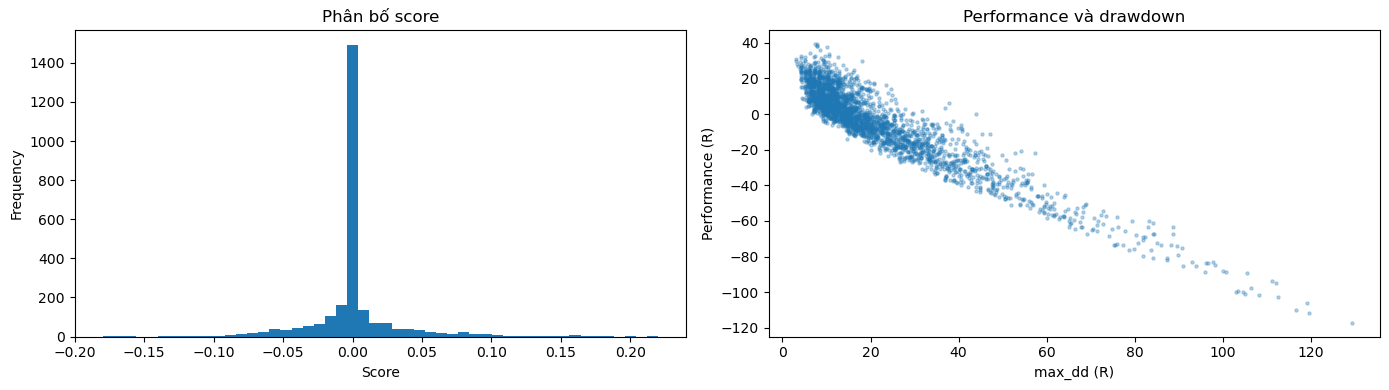

In [54]:
# Biểu đồ: phân bố score và hiệu quả theo drawdown
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()

Giai đoạn backtest: 2024-01-01 00:00:00 đến 2026-01-14 13:15:00
Tham số: {'boll_window': 200.0, 'boll_window_dev': 2.5, 'rsi_window': 14.0, 'rsi_threshold': 70.0, 'sl_multiplier': 0.25, 'tp_sl_ratio': 1.1}


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
backtest_trial,200,2.5,14,70,0.25,1.1,28.19589,8.69,1.59,0.921218,...,2.553771,0.451345,0.43841,9.241524,0.063978,149,1,79,0.125548,performance/number_of_trade*r2**5


,số lệnh
outcome,
take_profit,88
stop,60
end_of_data,1


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,tp_r,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,951,2024-01-10 21:45:00,1007,2024-01-11 11:45:00,38.176,1.291589,36.884411,39.596748,1.1,56,1,take_profit,1.1,0.029557,0.005173,1.065270
1,1019,2024-01-11 14:45:00,1024,2024-01-11 16:00:00,41.557,2.614726,38.942274,44.433199,1.1,5,1,stop,-1.0,0.015893,0.000248,-1.016142
2,1313,2024-01-14 16:15:00,1320,2024-01-14 18:00:00,37.849,0.755296,37.093704,38.679825,1.1,7,1,stop,-1.0,0.050111,0.001096,-1.051208
3,2443,2024-01-26 10:45:00,2466,2024-01-26 16:30:00,31.861,0.575786,31.285214,32.494364,1.1,23,1,take_profit,1.1,0.055335,0.003977,1.040688
4,2597,2024-01-28 01:15:00,2605,2024-01-28 03:15:00,34.272,1.069770,33.202230,35.448747,1.1,8,1,take_profit,1.1,0.032037,0.000801,1.067162
5,3115,2024-02-02 10:45:00,3169,2024-02-03 00:15:00,36.022,1.004349,35.017651,37.126784,1.1,54,1,take_profit,1.1,0.035866,0.006052,1.058082
6,3619,2024-02-07 16:45:00,3622,2024-02-07 17:30:00,35.021,0.333355,34.687645,35.387690,1.1,3,1,take_profit,1.1,0.105056,0.000985,0.993959
7,3796,2024-02-09 13:00:00,3806,2024-02-09 15:30:00,36.928,0.689427,36.238573,37.686370,1.1,10,1,take_profit,1.1,0.053563,0.001674,1.044763
8,3845,2024-02-10 01:15:00,3923,2024-02-10 20:45:00,38.940,1.323751,37.616249,40.396126,1.1,78,1,take_profit,1.1,0.029416,0.007170,1.063413
9,5435,2024-02-26 14:45:00,5438,2024-02-26 15:30:00,37.769,0.384880,37.384120,38.192368,1.1,3,1,take_profit,1.1,0.098132,0.000920,1.000948


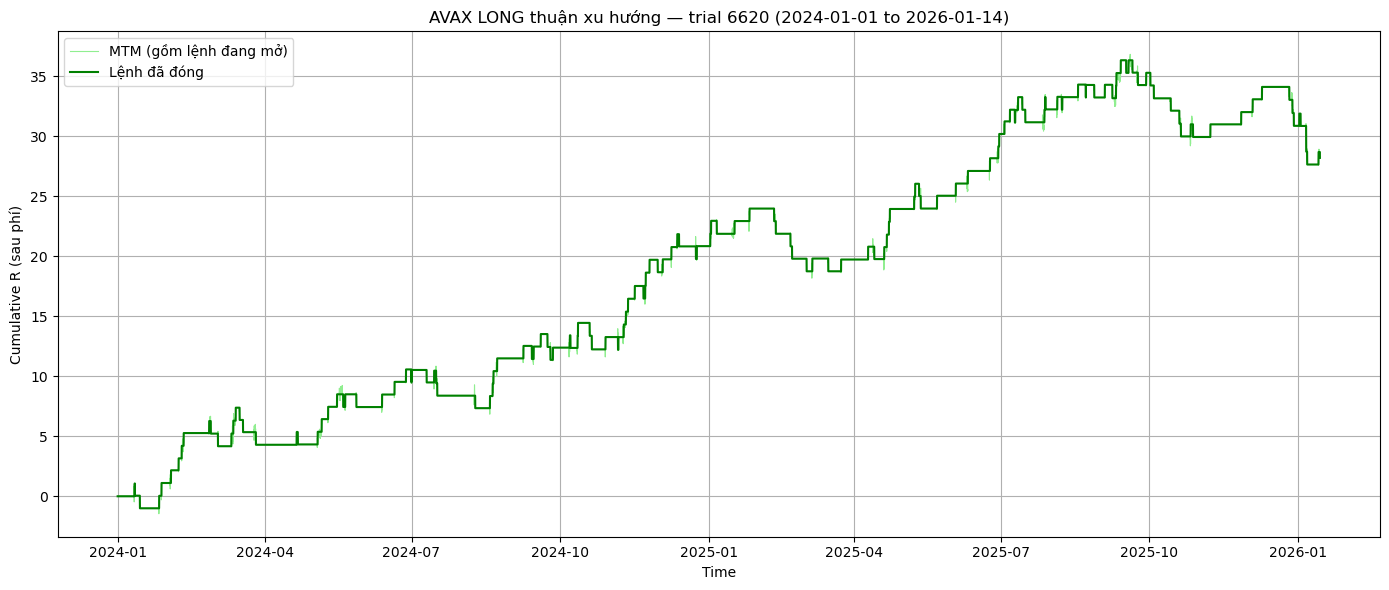

In [55]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = None  # Ví dụ "2025-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-01-14"    # Ví dụ "2026-01-14"; None = ngày kết thúc train

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
print("Tham số:", params)
display(backtest_trial.to_frame(name="backtest_trial").T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8, label="MTM (gồm lệnh đang mở)")
    ax.plot(equity["timestamp"], equity["closed_equity"], color="green", label="Lệnh đã đóng")
    ax.set(xlabel="Time", ylabel="Cumulative R (sau phí)",
           title=f"AVAX LONG thuận xu hướng — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()

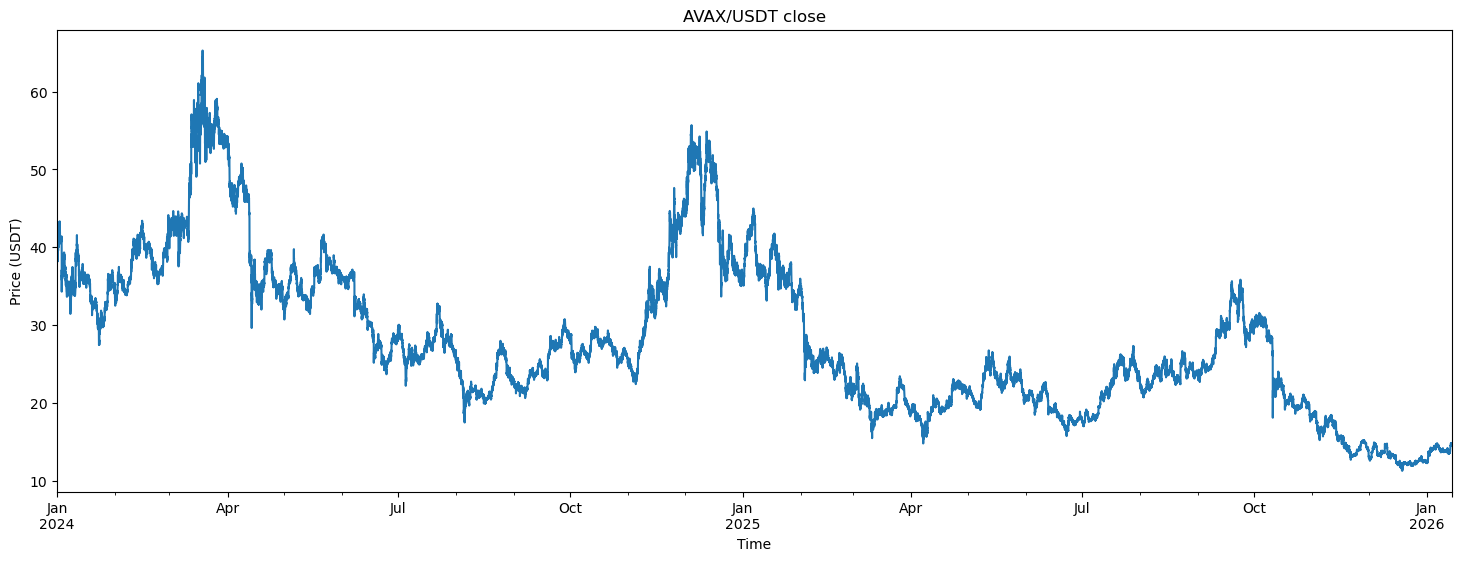

In [56]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()